# November 8 IMED archive | MATLAB, SciPy and JAX

Compare the two fitted models across all six recorded experiments in `MD_refit_ACTUAL_D_values_RES_20261108.mat`. The SciPy and JAX runs use the original archive inputs and the existing conservative PBM implementations. The MATLAB fit curves are recovered from the signed objective residuals and validated against the saved fit scores.

The supplied archive uses a 300-bin mesh from 0 to 3,000 µm. Both models have dissolution disabled. The saved plots retain measured observations as a separate series from archived MATLAB predictions.

### Saved results

Both solvers completed all 12 model–experiment combinations. Across those runs, the largest JAX–SciPy count RMSE was 0.487% of normalized peak, the largest concentration RMSE was 0.000435 g/g, and the largest final D10/D50/D90 difference was 0.573 µm. The largest API balance residual was 1.88e-13 g. The maximum final percentile difference from the archived MATLAB fit was 7.46 µm in Model 2, Experiment 6, where both Python solvers give D90 near 143.24 µm and MATLAB gives 135.78 µm.

## Paths and cases

The JAX implementation comes from the solver definition cells in `MainCode_Agg_Br.ipynb`. Its example recipe and plotting cells are skipped. Set the model and experiment lists to a subset for a shorter run. This notebook uses the installed local Python packages, including JAX, Diffrax, NumPy, SciPy, pandas, Matplotlib, and nbformat.

In [7]:
import os
import sys
from hashlib import sha256
from pathlib import Path
from time import perf_counter

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from IPython.display import display

archive_path = Path(
    r"C:/Users/abotondo/OneDrive - purdue.edu/Pfizer/2. Purdue Experiments/"
    "Evaluated expts/IMED_files/MD_refit_ACTUAL_D_values_RES_20261108.mat"
)
jax_notebook = Path(r"C:/Users/abotondo/4. FVM_solver/MainCode_Agg_Br.ipynb")
model_ids = [1, 2]
experiment_ids = [1, 2, 3, 4, 5, 6]
plot_model, plot_experiment = 2, 1

# Only raise the wall-clock timeout. Keep the archived numerical tolerances.
wall_clock_limit_s = 180

root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "imed_python" / "solver.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook from the IMED repository or a folder inside it.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from imed_python.distribution import cell_volumes, volume_distribution
from imed_python.solver import load_case, model_parameters, profile, simulate as simulate_scipy
from imed_python.validation.compare_matlab import recover_predictions

jax_code = nbformat.read(jax_notebook, as_version=4)
jax_sources = [
    next(cell.source for cell in jax_code.cells
         if cell.cell_type == "code" and marker in cell.source)
    for marker in ("from diffrax import", "class PBMArguments", "def simulate_jax(")
]
jax_namespace = {"__name__": "__main__"}
for source in jax_sources:
    exec(compile(source, str(jax_notebook), "exec"), jax_namespace)
simulate_jax = jax_namespace["simulate_jax"]

print("Archive", archive_path.name)
print("Archive SHA256", sha256(archive_path.read_bytes()).hexdigest())
print("SciPy solver SHA256", sha256((root / "imed_python" / "solver.py").read_bytes()).hexdigest())
print("JAX definition SHA256", sha256("\n".join(jax_sources).encode()).hexdigest())
print("JAX devices", jax_namespace["jax"].devices())

Archive MD_refit_ACTUAL_D_values_RES_20261108.mat
Archive SHA256 eff04ea3896e00e54330f26ffc1a1da528947b7c874597cb0016f96dfcb77e4e
SciPy solver SHA256 4b796363a26bbeeeae1fdb3261c299321ac9a4d54457983a5f1db5e2ac4613f2
JAX definition SHA256 d1da70183776dbb639117733ee470564026623fb8957170973d5cd5470748644
JAX devices [CpuDevice(id=0)]


## Inspect the archive inputs

The archived initial CSD array is used directly, along with seed and solvent masses, initial concentration, densities, shape factor, feed and temperature history, and the fitted kinetic vector for each model. The seed percentiles in the table are archived metadata. The actual seed CSD comes from the saved distribution array.

In [2]:
archive = load_case(archive_path)
settings = dict(archive["pbmsetting"])
print("Archived settings", settings)
print("Archived solubility coefficients", archive["Solubility"])
settings["MaxIterationTime"] = wall_clock_limit_s

for selected, limit in ((model_ids, len(archive["ModelParameter"])),
                        (experiment_ids, len(archive["ExpData"]))):
    if not selected or len(selected) != len(set(selected)) or not all(1 <= i <= limit for i in selected):
        raise ValueError("Select distinct one-based archive IDs in range.")

references = {
    model: recover_predictions(archive, archive["ModelParameter"][model - 1])
    for model in model_ids
}
parameters_by_model = {
    model: model_parameters(archive["ModelParameter"][model - 1])
    for model in model_ids
}

input_rows = []
for experiment_id in experiment_ids:
    experiment = archive["ExpData"][experiment_id - 1]
    process = archive["ProcInf"][experiment_id - 1]
    temp_time, temperatures = experiment["TemperatureData"]
    flow_time, flow = experiment["FlowRateData"]
    input_rows.append({
        "Experiment": experiment_id,
        "Duration (h)": temp_time[-1] / 3600,
        "Initial T (°C)": temperatures[0],
        "Final T (°C)": temperatures[-1],
        "AS added (g)": np.trapezoid(flow, flow_time),
        "Seed (g)": process["SeedMass"],
        "Initial c (g/g)": experiment["ConcentrationData"][1, 0],
        **{f"Seed D{d} (µm)": value for d, value in zip((10, 50, 90), experiment["InitialD10D50D90"])},
    })
input_summary = pd.DataFrame(input_rows).set_index("Experiment")
display(input_summary.round(6))

Archived settings {'RelTol': 1e-05, 'AbsTol': 1e-05, 'MaxIterationTime': 30, 'Lmin': 0, 'Lmax': 3000, 'N': 300}
Archived solubility coefficients {'a': 8.41099454, 'b': -2365.44505557, 'c': 0, 'd': 0, 'e': -3.7514391, 'f': 0, 'g': 0, 'h': 0}


,Duration (h),Initial T (°C),Final T (°C),AS added (g),Seed (g),Initial c (g/g),Seed D10 (µm),Seed D50 (µm),Seed D90 (µm)
Experiment,,,,,,,,,
1,24.140278,64.827713,22.568245,245.156432,1.088000,0.096614,13.5,23.6,38.4
2,22.185556,65.113762,23.838432,232.916099,0.021760,0.096696,13.5,23.6,38.4
3,19.019167,64.792030,23.746105,231.113554,0.163200,0.097338,15.4,27.9,50.2
4,20.469167,65.763474,23.736631,243.734346,0.435200,0.098995,15.4,27.9,50.2
5,20.796667,65.095016,31.074728,247.074566,0.435200,0.097988,15.4,27.9,50.2
6,12.568889,64.583794,23.851536,212.611320,0.347153,0.096776,16.0,26.0,43.0


## Run both PBMs

Each solver receives the same input dictionaries and the archived relative and absolute tolerances. The timeout allowance is 180 s per SciPy solve. Timing includes solver setup and host output conversion. JAX timing can include compilation for a new profile shape.

Archived count curves are normalized to their own peak on the observation grid, matching the MATLAB fitting convention. Concentration and normalized count RMSE use the archived observation times. Final D10/D50/D90 use the production volume-percentile calculation for both PBMs. Material balance includes API transported beyond the size mesh.

In [3]:
def peak_normalized(values):
    peak = np.max(values)
    if not peak > 0:
        raise ValueError("Cannot normalize an empty count signal.")
    return values / peak


def rmse(actual, reference):
    return np.sqrt(np.mean((actual - reference)**2))


def solve_recipe(solver, parameters, experiment, process, settings):
    started = perf_counter()
    count, concentration, csd, history = solver(
        parameters, experiment, process, archive["Solubility"], settings, return_history=True,
    )
    elapsed = perf_counter() - started
    n = int(settings["N"])
    edges = np.linspace(settings["Lmin"], settings["Lmax"], n + 1)
    volume = cell_volumes(edges, process["ShapeFactor"])
    solid = (volume * np.diff(edges)) @ history[:n] * process["SolidDensity"] / 1e12
    dissolved = history[n] * history[n + 1]
    off_grid = history[n + 5]
    initial_c = experiment["ConcentrationData"][1, 0]
    carrier = process["SolvMass"] + process["AntiSolvMass"]
    charge = process["SeedMass"] + carrier * initial_c / (1 - initial_c)
    balance = solid + dissolved + off_grid - charge
    distribution, sizes = volume_distribution(csd, process, settings)

    count_time, _ = experiment["CountsData"]
    c_time, _ = experiment["ConcentrationData"]
    time = count[0]
    if min(count_time[0], c_time[0]) < time[0] or max(count_time[-1], c_time[-1]) > time[-1]:
        raise ValueError("The observation grid lies outside the simulation time domain.")
    return {
        "time": time, "count": count[1], "concentration": concentration[1],
        "count_at_obs": peak_normalized(np.interp(count_time, *count)),
        "c_at_obs": np.interp(c_time, *concentration),
        "volume_csd": distribution, "D": sizes, "balance_g": balance,
        "solid_g": solid, "dissolved_g": dissolved, "off_grid_g": off_grid,
        "antisolvent_fraction": 1 - history[n + 2],
        "elapsed_s": elapsed, "charge_g": charge,
    }


runs = {}
rows = []
for model in model_ids:
    for experiment_id in experiment_ids:
        experiment = archive["ExpData"][experiment_id - 1]
        process = archive["ProcInf"][experiment_id - 1]
        reference = references[model][experiment_id - 1] if experiment_id <= len(references[model]) else None
        row = {"Model": model, "Experiment": experiment_id, "MATLAB reference": reference is not None}
        for label, solver in (("SciPy", simulate_scipy), ("JAX", simulate_jax)):
            try:
                result = solve_recipe(solver, parameters_by_model[model], experiment, process, settings)
            except (ArithmeticError, RuntimeError, TimeoutError, ValueError) as error:
                row[f"{label} status"] = f"{type(error).__name__}. {error}"
                continue
            runs[model, experiment_id, label] = result
            row[f"{label} status"] = "Completed"
            row[f"{label} runtime (s)"] = result["elapsed_s"]
            row[f"{label} API balance max (g)"] = np.max(np.abs(result["balance_g"]))
            row[f"{label} final off-grid API (g)"] = result["off_grid_g"][-1]
            row[f"{label} final c (g/g)"] = result["concentration"][-1]
            if result["D"] is not None:
                for p, size in zip((10, 50, 90), result["D"]):
                    row[f"{label} final D{p} (µm)"] = size
            if reference is not None:
                ref_count, ref_c, ref_sizes = reference
                row[f"{label} vs MATLAB count RMSE (%)"] = 100 * rmse(result["count_at_obs"], ref_count)
                row[f"{label} vs MATLAB c RMSE (g/g)"] = rmse(result["c_at_obs"], ref_c)
                if result["D"] is not None:
                    row[f"{label} vs MATLAB max D error (µm)"] = np.max(np.abs(result["D"] - ref_sizes))

        if reference is not None:
            row["MATLAB final c (g/g)"] = reference[1][-1]
            for p, size in zip((10, 50, 90), reference[2]):
                row[f"MATLAB final D{p} (µm)"] = size
        row["Measured final c (g/g)"] = experiment["ConcentrationData"][1, -1]
        for p, size in zip((10, 50, 90), experiment["FinalD10D50D90"]):
            row[f"Measured final D{p} (µm)"] = size

        pair = [runs.get((model, experiment_id, label)) for label in ("SciPy", "JAX")]
        if all(value is not None for value in pair):
            scipy_run, jax_run = pair
            row["JAX vs SciPy count RMSE (%)"] = 100 * rmse(jax_run["count_at_obs"], scipy_run["count_at_obs"])
            row["JAX vs SciPy c RMSE (g/g)"] = rmse(jax_run["c_at_obs"], scipy_run["c_at_obs"])
            if all(result["D"] is not None for result in pair):
                row["JAX vs SciPy max D error (µm)"] = np.max(np.abs(jax_run["D"] - scipy_run["D"]))
        rows.append(row)
        print(f"Model {model}, experiment {experiment_id}. "
              f"SciPy {row['SciPy status']}, JAX {row['JAX status']}.", flush=True)

summary = pd.DataFrame(rows).set_index(["Model", "Experiment"])

Model 1, experiment 1. SciPy Completed, JAX Completed.
Model 1, experiment 2. SciPy Completed, JAX Completed.


C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\GIT\Orhcestrator\imed_python\solver.py:258: RuntimeWarning: divide by zero encountered in scalar divide
  ratio = solute if matlab_pe else solute / liquid_mass
C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\GIT\Orhcestrator\imed_python\solver.py:265: RuntimeWarning: invalid value encountered in scalar divide
  supersat = ratio / (1 + ratio) / saturation - 1
C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\GIT\Orhcestrator\imed_python\solver.py:332: RuntimeWarning: divide by zero encountered in scalar divide
  inflow, -solvent * inflow / liquid_mass,
C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\GIT\Orhcestrator\imed_python\solver.py:263: RuntimeWarning: invalid value encountered in scalar multiply
  + d * anti + e * np.exp(anti) + f * anti**2
C:\Users\abotondo\OneDrive - purdue.edu\ECNDATA\Desktop\GIT\Orhcestrator\imed_python\solver.py:264: RuntimeWarning: invalid value encountered in scalar multiply
  + 

Model 1, experiment 3. SciPy Completed, JAX Completed.
Model 1, experiment 4. SciPy Completed, JAX Completed.
Model 1, experiment 5. SciPy Completed, JAX Completed.
Model 1, experiment 6. SciPy Completed, JAX Completed.
Model 2, experiment 1. SciPy Completed, JAX Completed.
Model 2, experiment 2. SciPy Completed, JAX Completed.
Model 2, experiment 3. SciPy Completed, JAX Completed.
Model 2, experiment 4. SciPy Completed, JAX Completed.
Model 2, experiment 5. SciPy Completed, JAX Completed.
Model 2, experiment 6. SciPy Completed, JAX Completed.


## Compare all cases

Each row compares one fitted model and experiment. Concentration errors are in g/g solution. Count RMSE is a percentage of the normalized count scale. Size error is the largest absolute difference among final volume D10, D50 and D90.

In [4]:
for reference_label in ("MATLAB", "SciPy"):
    candidates = ("SciPy", "JAX") if reference_label == "MATLAB" else ("JAX",)
    columns = [
        f"{candidate} vs {reference_label} {metric}"
        for candidate in candidates
        for metric in ("count RMSE (%)", "c RMSE (g/g)", "max D error (µm)")
    ]
    available = summary.reindex(columns=columns)
    display(available.style.format("{:.5g}", na_rep="—"))

display(summary.reindex(columns=[
    "SciPy status", "JAX status", "SciPy API balance max (g)", "JAX API balance max (g)",
    "SciPy final off-grid API (g)", "JAX final off-grid API (g)",
]).style.format("{:.4g}", subset=[
    "SciPy API balance max (g)", "JAX API balance max (g)",
    "SciPy final off-grid API (g)", "JAX final off-grid API (g)",
], na_rep="—"))

## Plot a selected experiment and model

Edit `plot_model` and `plot_experiment` near the top, then rerun this cell after the comparison. MATLAB predictions are available for concentration, normalized counts and final percentiles. The archive does not supply a fitted volume distribution or time-resolved API inventory for plotting, so those panels show the two PBMs.

In [6]:
case_key

(2, 6)

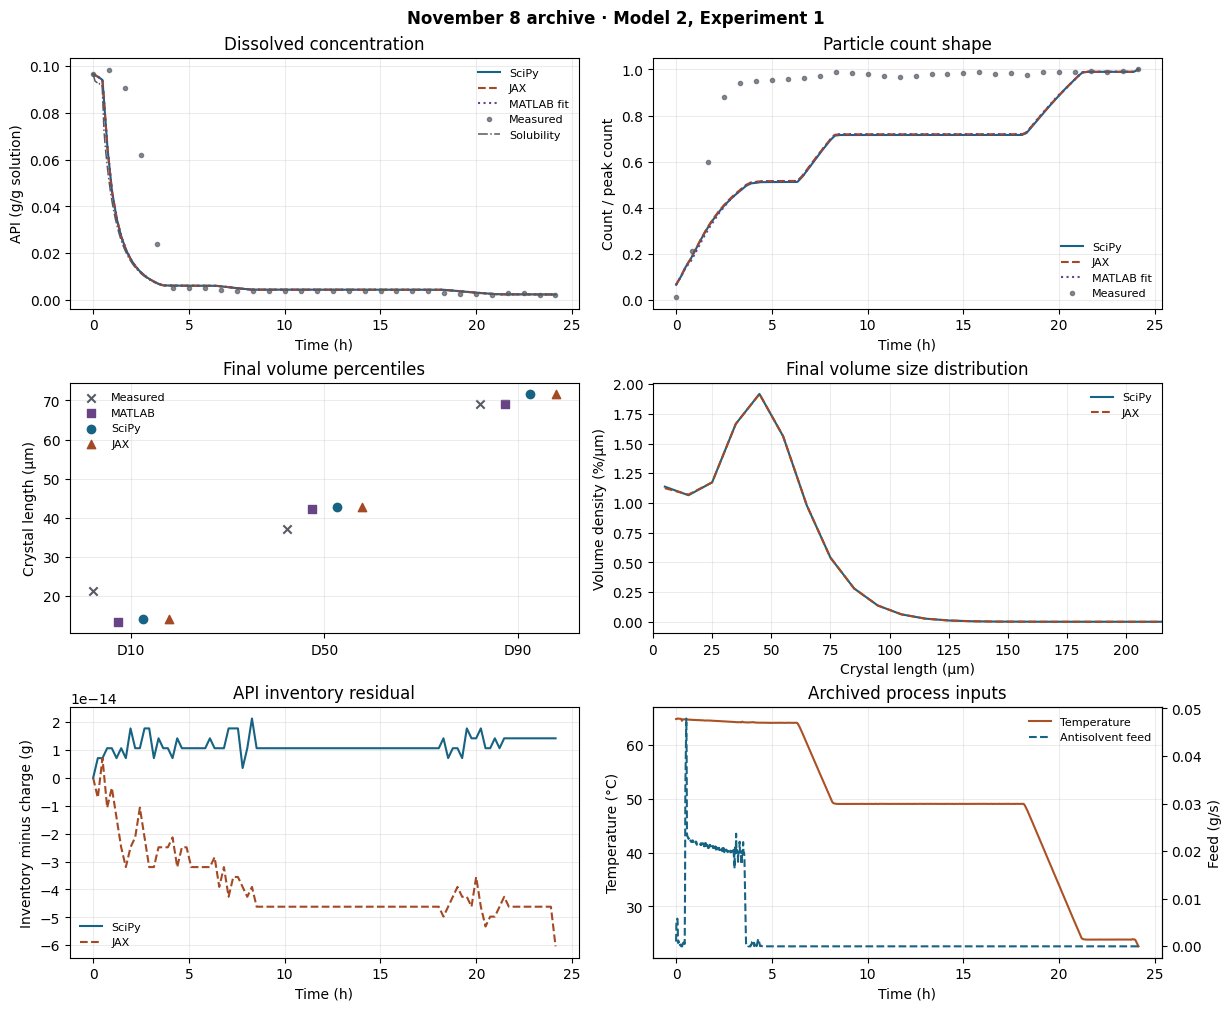

In [8]:
case_key = plot_model, plot_experiment
if case_key not in summary.index:
    case_key = summary.index[0]
model, experiment_id = case_key
experiment = archive["ExpData"][experiment_id - 1]
case_runs = {name: runs[model, experiment_id, name] for name in ("SciPy", "JAX")
             if (model, experiment_id, name) in runs}
matlab = references[model][experiment_id - 1] if experiment_id <= len(references[model]) else None
tc, measured_c = experiment["ConcentrationData"]
tn, measured_n = experiment["CountsData"]
styles = {
    "SciPy": {"color": "#176383", "linestyle": "-"},
    "JAX": {"color": "#a34924", "linestyle": "--"},
    "MATLAB": {"color": "#684385", "linestyle": ":"},
    "Measured": {"color": "#565b64", "linestyle": "None", "marker": ".", "markevery": 50, "alpha": .7},
}

fig, axes = plt.subplots(3, 2, figsize=(12.2, 10), layout="constrained")
fig.suptitle(f"November 8 archive · Model {model}, Experiment {experiment_id}", fontweight="bold")
c_ax, n_ax, d_ax, csd_ax, mass_ax, inputs_ax = axes.flat
for name, data in case_runs.items():
    c_ax.plot(tc / 3600, data["c_at_obs"], label=name, **styles[name])
    n_ax.plot(tn / 3600, data["count_at_obs"], label=name, **styles[name])
    csd_ax.plot(*data["volume_csd"], label=name, **styles[name])
    mass_ax.plot(data["time"] / 3600, data["balance_g"], label=name, **styles[name])
if matlab is not None:
    n_ax.plot(tn / 3600, matlab[0], label="MATLAB fit", **styles["MATLAB"])
    c_ax.plot(tc / 3600, matlab[1], label="MATLAB fit", **styles["MATLAB"])
n_ax.plot(tn / 3600, peak_normalized(measured_n), label="Measured", **styles["Measured"])
c_ax.plot(tc / 3600, measured_c, label="Measured", **styles["Measured"])

for index, (name, values) in enumerate((
    ("Measured", experiment["FinalD10D50D90"]),
    ("MATLAB", None if matlab is None else matlab[2]),
    *[(name, data["D"]) for name, data in case_runs.items()],
)):
    if values is not None:
        d_ax.scatter(np.arange(3) + (index - 1.5) * .13, values,
                     color=styles[name]["color"], marker=("x", "s", "o", "^")[index], label=name)
d_ax.set_xticks(np.arange(3), ["D10", "D50", "D90"])

temperature_time, temperature = experiment["TemperatureData"]
flow_time, flow = experiment["FlowRateData"]
# Integrate the archived piecewise-linear feed and evaluate the full IMED solubility law.
from scipy.interpolate import make_interp_spline

process = archive["ProcInf"][experiment_id - 1]
feed_integral = make_interp_spline(flow_time, flow, k=1).antiderivative()
as_mass = process["AntiSolvMass"] + feed_integral(tc) - feed_integral(0.)
as_fraction = as_mass / (process["SolvMass"] + as_mass)
kelvin = profile(experiment["TemperatureData"])(tc) + 273.15
a, b, c, d, e, f, g, h = (archive["Solubility"][key] for key in "abcdefgh")
c_sat = np.exp(a + b / kelvin + c * np.log(kelvin) + d * as_fraction
               + e * np.exp(as_fraction) + f * as_fraction**2
               + g * as_fraction / kelvin + h * np.exp(as_fraction) / kelvin)
c_ax.plot(tc / 3600, c_sat, color="0.35", ls="-.", lw=1.1, label="Solubility")
t_line, = inputs_ax.plot(temperature_time / 3600, temperature, color="#aa5125", label="Temperature")
feed_ax = inputs_ax.twinx()
f_line, = feed_ax.plot(flow_time / 3600, flow, color="#176383", ls="--", label="Antisolvent feed")
inputs_ax.legend(handles=[t_line, f_line], frameon=False, fontsize=8)
feed_ax.set_ylabel("Feed (g/s)")
feed_ax.grid(False)

c_ax.set(title="Dissolved concentration", ylabel="API (g/g solution)", xlabel="Time (h)")
n_ax.set(title="Particle count shape", ylabel="Count / peak count", xlabel="Time (h)")
d_ax.set(title="Final volume percentiles", ylabel="Crystal length (µm)")
csd_ax.set(title="Final volume size distribution", ylabel="Volume density (%/µm)", xlabel="Crystal length (µm)")
mass_ax.set(title="API inventory residual", ylabel="Inventory minus charge (g)", xlabel="Time (h)")
inputs_ax.set(title="Archived process inputs", ylabel="Temperature (°C)", xlabel="Time (h)")
if case_runs:
    resolved_sizes = [data["D"][2] for data in case_runs.values() if data["D"] is not None]
    if resolved_sizes:
        csd_ax.set_xlim(0, min(settings["Lmax"], 3 * max(resolved_sizes)))
for ax in axes.flat:
    ax.grid(alpha=.23)
    if ax is not inputs_ax and ax.get_legend_handles_labels()[0]:
        ax.legend(frameon=False, fontsize=8)
plt.show()

## Interpretation

Agreement between JAX and SciPy tests the two conservative implementations on the same archived inputs. Differences from the archived fit can also reflect the historical MATLAB PE discretization and its use during parameter fitting. The comparison preserves the archived kinetics for both Python solvers.